# Example metrics reporting: grain-size classification

This notebook reports outer-fold metrics for the five trained models and four ensemble methods. It presents aggregated accuracy, macro precision, macro recall, macro F1-score, and multiclass MCC for every method, followed by per-class precision, recall, and F1-score for the globally weighted probability ensemble. Exact confusion matrices and one-vs-rest precision-recall curves are shown for all methods. The four ensemble methods combine the pretrained EfficientNetV2-S, ViT-Tiny, Swin-Tiny, and ConvNeXt-Tiny models, while Small CNN is retained as a standalone baseline.

All predictions are pooled outer-held-out predictions. Additional tables report outer-fold mean/standard deviation and timing. The last configuration table describes separate deployment fits. Retained outputs are historical until rerun.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (
    (PROJECT_ROOT / "Source").is_dir()
    and (PROJECT_ROOT / "Notebooks").is_dir()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (
    (PROJECT_ROOT / "Source").is_dir()
    and (PROJECT_ROOT / "Notebooks").is_dir()
):
    raise RuntimeError(
        "Could not locate project root containing Source and Notebooks."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.metrics_reporting import (
    calculate_method_metrics,
    load_best_grid_search_configurations,
    load_method_predictions,
    print_latex_best_backbones_by_class,
    print_latex_best_grid_search_configurations,
    plot_exact_confusion_matrices,
    plot_multiclass_precision_recall_curves,
    print_latex_metric_tables,
)
from Source.cross_validation import read_cv_plan

In [2]:
RESULTS_ROOT = PROJECT_ROOT / "Results"
ENSEMBLE_RESULTS = RESULTS_ROOT / "gs_ensemble" / "cross_validation" / "oof_predictions.csv"
CLASS_CODES = [11, 12, 13]
CLASS_NAMES = {
    11: "Fine (<4 mm d50)",
    12: "Medium (4-32 mm d50)",
    13: "Coarse (>32 mm d50)",
}

METHOD_SPECS = [
    {"name": "Small CNN", "type": "Model", "path": RESULTS_ROOT / "gs_small_cnn" / "cross_validation" / "oof_predictions.csv", "prediction_column": "predicted_class_code"},
    {"name": "EfficientNetV2-S", "type": "Model", "path": RESULTS_ROOT / "gs_efficientnetv2_s" / "cross_validation" / "oof_predictions.csv", "prediction_column": "predicted_class_code"},
    {"name": "ViT-Tiny", "type": "Model", "path": RESULTS_ROOT / "gs_vit_tiny" / "cross_validation" / "oof_predictions.csv", "prediction_column": "predicted_class_code"},
    {"name": "Swin-Tiny", "type": "Model", "path": RESULTS_ROOT / "gs_swin_tiny" / "cross_validation" / "oof_predictions.csv", "prediction_column": "predicted_class_code"},
    {"name": "ConvNeXt-Tiny", "type": "Model", "path": RESULTS_ROOT / "gs_convnext_tiny" / "cross_validation" / "oof_predictions.csv", "prediction_column": "predicted_class_code"},
    {"name": "Hard voting", "type": "Ensemble", "path": ENSEMBLE_RESULTS, "prediction_column": "hard_voting_predicted_class_code"},
    {"name": "Probability voting", "type": "Ensemble", "path": ENSEMBLE_RESULTS, "prediction_column": "probability_voting_predicted_class_code"},
    {"name": "Globally weighted probability voting", "type": "Ensemble", "path": ENSEMBLE_RESULTS, "prediction_column": "weighted_probability_per_model_predicted_class_code"},
    {"name": "Model-and-class weighted probability voting", "type": "Ensemble", "path": ENSEMBLE_RESULTS, "prediction_column": "weighted_probability_per_model_class_predicted_class_code"},
]

print(f"Results root: {RESULTS_ROOT}")
print(f"Configured methods: {len(METHOD_SPECS)}")

Results root: /Users/piotr/Praca/Nauka/publikacje/Beach_classification/Beach_classification_software/pmaciag-volume-beach/Results
Configured methods: 9


In [3]:
_, _, cv_manifest = read_cv_plan(PROJECT_ROOT / "Data" / "Preprocessed")
predictions = load_method_predictions(METHOD_SPECS, CLASS_CODES, expected_cv_manifest=cv_manifest)
aggregate_metrics, per_class_metrics, confusion_matrices = calculate_method_metrics(
    predictions,
    CLASS_CODES,
    CLASS_NAMES,
)
DETAILED_ENSEMBLE_NAME = "Globally weighted probability voting"
selected_per_class_metrics = per_class_metrics.loc[
    per_class_metrics["Method"] == DETAILED_ENSEMBLE_NAME,
    ["Class", "Class name", "Precision", "Recall", "F1-score"],
].reset_index(drop=True)

print("Aggregated outer-fold metrics")
display(aggregate_metrics.style.format(precision=3))

print(f"Per-class outer-fold metrics: {DETAILED_ENSEMBLE_NAME}")
display(selected_per_class_metrics.style.format(precision=3))

Aggregated test-set metrics


,Method,Type,Accuracy,Macro precision,Macro recall,Macro F1,MCC
0,Small CNN,Model,0.667,0.663,0.731,0.670,0.518
1,EfficientNetV2-S,Model,0.667,0.663,0.731,0.670,0.518
2,ViT-Tiny,Model,0.667,0.696,0.685,0.661,0.528
3,Swin-Tiny,Model,0.667,0.667,0.685,0.657,0.512
4,ConvNeXt-Tiny,Model,0.857,0.867,0.880,0.863,0.786
5,Hard voting,Ensemble,0.857,0.847,0.884,0.852,0.790
6,Probability voting,Ensemble,0.857,0.847,0.884,0.852,0.790
7,Globally weighted probability voting,Ensemble,0.857,0.847,0.884,0.852,0.790
8,Model-and-class weighted probability voting,Ensemble,0.762,0.774,0.806,0.763,0.657


Per-class test-set metrics: Globally weighted probability voting


,Class,Class name,Precision,Recall,F1-score
0,11,Fine (<4 mm d50),0.667,1.000,0.800
1,12,Medium (4-32 mm d50),0.875,0.778,0.824
2,13,Coarse (>32 mm d50),1.000,0.875,0.933


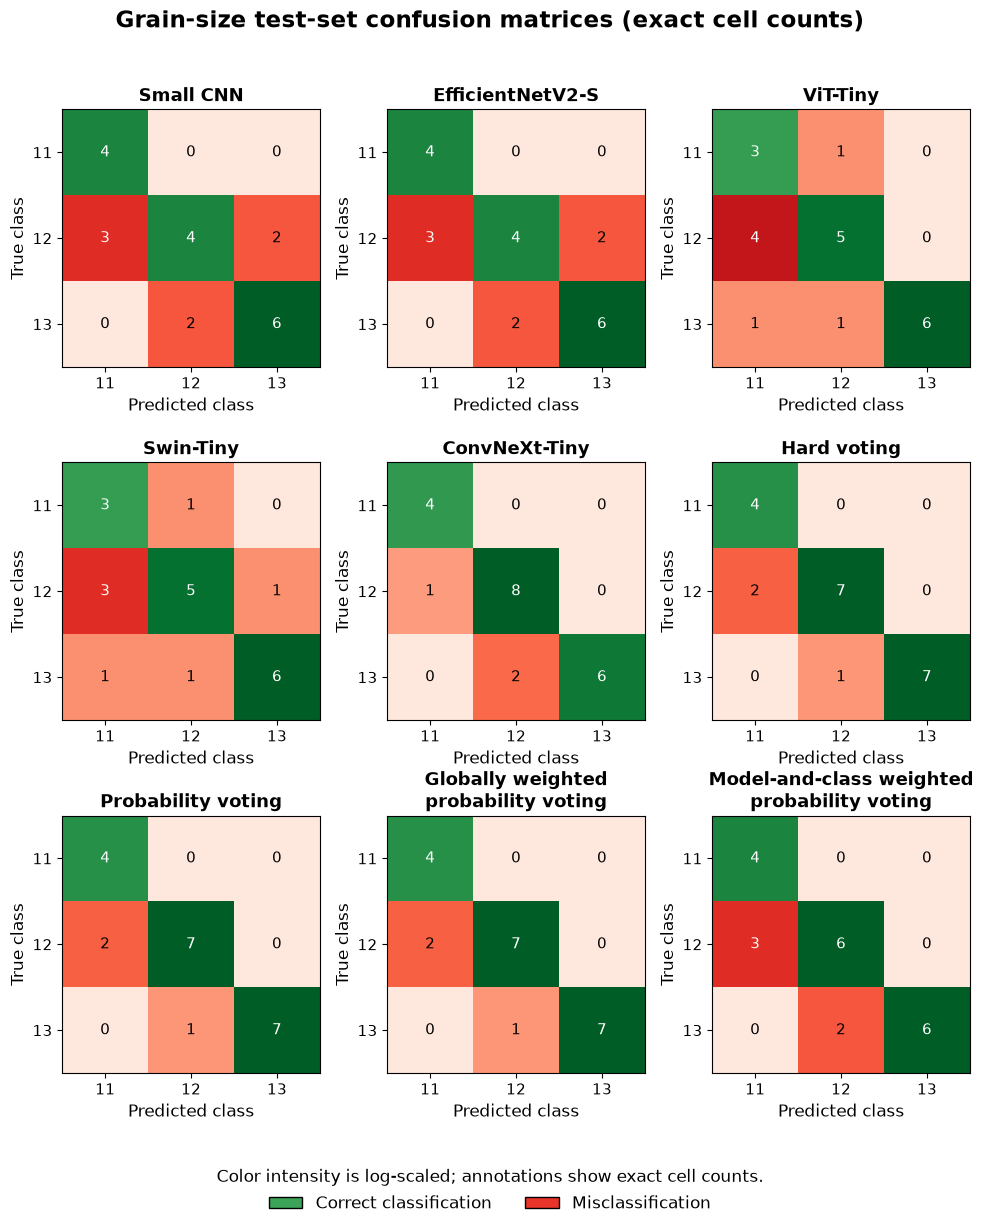

In [4]:
confusion_figure = plot_exact_confusion_matrices(
    confusion_matrices,
    CLASS_CODES,
    "Grain-size outer-fold confusion matrices (exact cell counts)",
    panel_size=3.3,
    font_scale=1.20,
)
plt.show()

In [5]:
print_latex_metric_tables(
    aggregate_metrics,
    selected_per_class_metrics,
    confusion_matrices,
    CLASS_CODES,
    evaluation_label="pooled outer-fold",
    dataset_label="grain-size classification dataset",
    label_prefix="grain-size",
    per_class_method_label=DETAILED_ENSEMBLE_NAME,
)

% Aggregate metrics
\begin{longtable}{lrrrrr}
\caption{Aggregated test-set metrics for the grain-size classification dataset.} \label{tab:grain-size-aggregate-metrics} \\
\toprule
\textbf{Method} & \textbf{Acc.} & \textbf{Prec.} & \textbf{Rec.} & \textbf{F1-score} & \textbf{MCC} \\
\midrule
\endfirsthead
\caption[]{Aggregated test-set metrics for the grain-size classification dataset.} \\
\toprule
\textbf{Method} & \textbf{Acc.} & \textbf{Prec.} & \textbf{Rec.} & \textbf{F1-score} & \textbf{MCC} \\
\midrule
\endhead
\midrule
\multicolumn{6}{r}{Continued on next page} \\
\midrule
\endfoot
\bottomrule
\endlastfoot
Small CNN & 0.667 & 0.663 & 0.731 & 0.670 & 0.518 \\
EfficientNetV2-S & 0.667 & 0.663 & 0.731 & 0.670 & 0.518 \\
ViT-Tiny & 0.667 & 0.696 & 0.685 & 0.661 & 0.528 \\
Swin-Tiny & 0.667 & 0.667 & 0.685 & 0.657 & 0.512 \\
ConvNeXt-Tiny & \cellcolor{gray!25}0.857 & \cellcolor{gray!25}0.867 & 0.880 & \cellcolor{gray!25}0.863 & 0.786 \\
\midrule
Hard voting & \cellcolor{gray!25}0.857 

In [6]:
print_latex_best_backbones_by_class(
    per_class_metrics,
    dataset_label="grain-size classification dataset",
    label_prefix="grain-size",
)

% Best standalone backbone by class and metric
\begin{longtable}{@{}rlccccc@{}}
\caption{Standalone backbones achieving the highest class-specific F1-score in the grain-size classification dataset. An X identifies the best result; exact ties are retained.} \label{tab:grain-size-best-backbone-per-class} \\
\toprule
\textbf{Class} & \textbf{Class name} & \shortstack{\textbf{Small}\\\textbf{CNN}} & \shortstack{\textbf{EfficientNet}\\\textbf{V2-S}} & \shortstack{\textbf{ViT}\\\textbf{Tiny}} & \shortstack{\textbf{Swin}\\\textbf{Tiny}} & \shortstack{\textbf{ConvNeXt}\\\textbf{Tiny}} \\
\midrule
\endfirsthead
\caption[]{Standalone backbones achieving the highest class-specific F1-score in the grain-size classification dataset.} \\
\toprule
\textbf{Class} & \textbf{Class name} & \shortstack{\textbf{Small}\\\textbf{CNN}} & \shortstack{\textbf{EfficientNet}\\\textbf{V2-S}} & \shortstack{\textbf{ViT}\\\textbf{Tiny}} & \shortstack{\textbf{Swin}\\\textbf{Tiny}} & \shortstack{\textbf{ConvNeXt}\\\tex

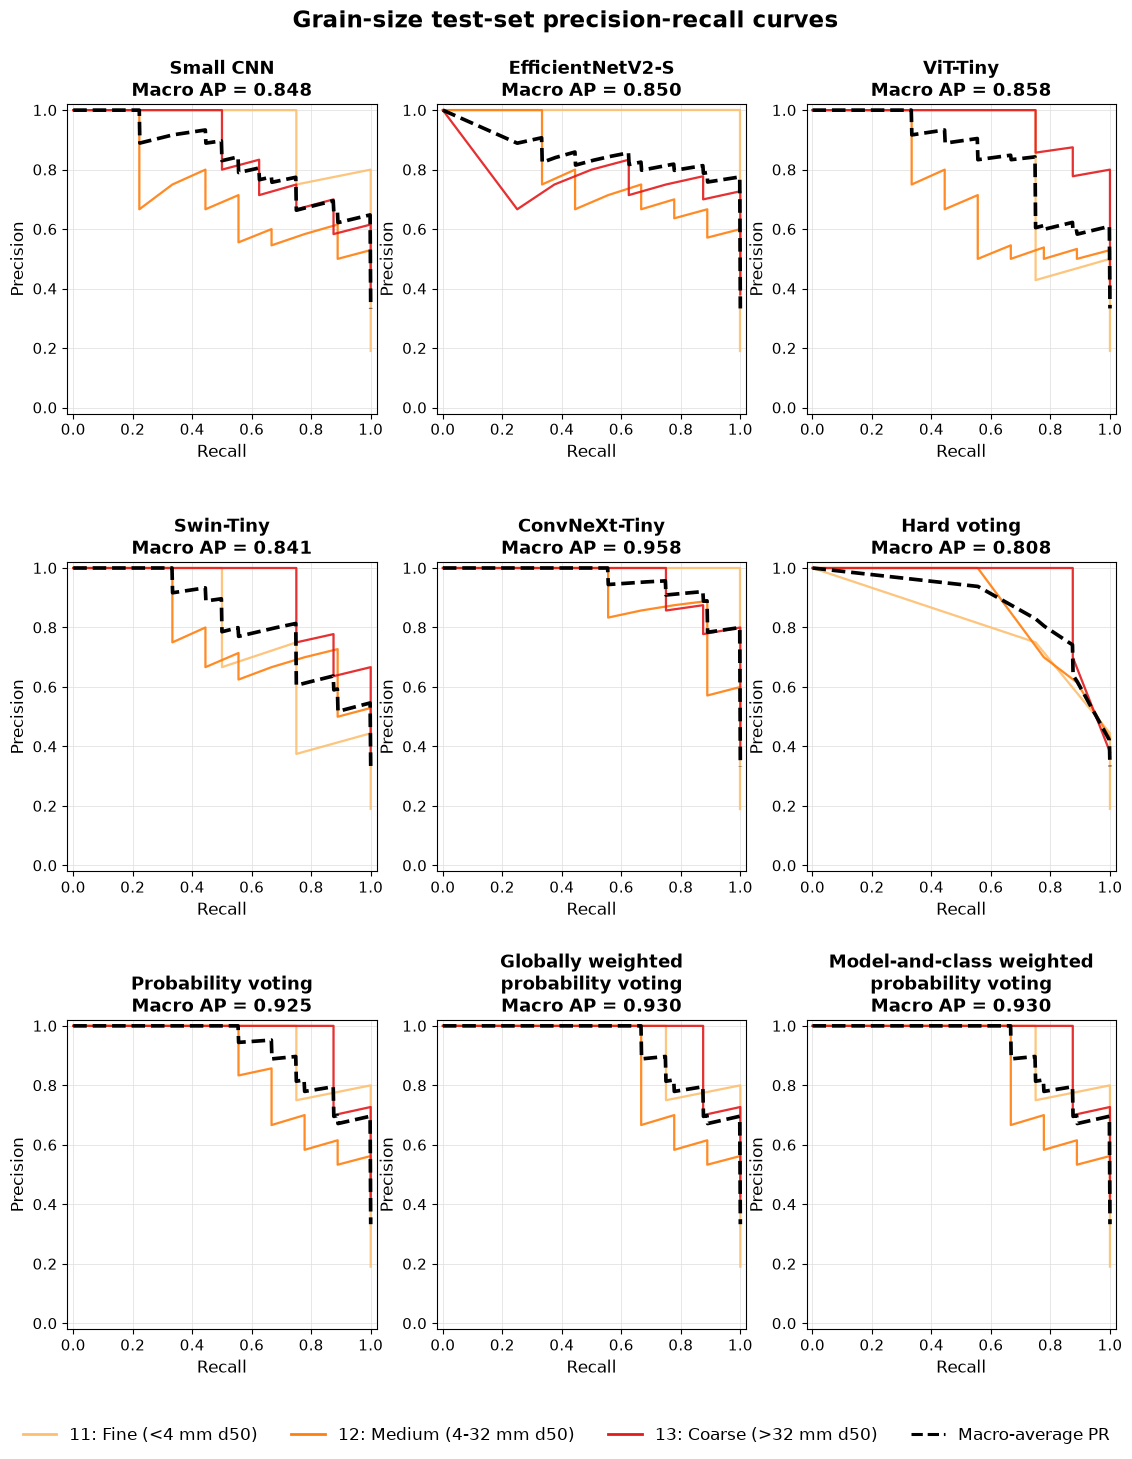

In [7]:
precision_recall_figure = plot_multiclass_precision_recall_curves(
    predictions,
    CLASS_CODES,
    CLASS_NAMES,
    "Grain-size outer-fold precision-recall curves",
    panel_size=3.6,
    font_scale=1.20,
)
plt.show()

In [8]:
print("Separate deployment configurations: outer-fold evaluation uses fold-specific selections.")
best_grid_search_configurations = load_best_grid_search_configurations(METHOD_SPECS)
display(
    best_grid_search_configurations.style.format(
        {
            "Learning rate": "{:.0e}",
            "Weight decay": "{:.0e}",
            "Dropout": "{:g}",
            "Validation macro F1": "{:.3f}",
        },
        na_rep="--",
    )
)
print_latex_best_grid_search_configurations(
    best_grid_search_configurations,
    selection_description="averaged across inner folds for separate all-data deployment fits",
    dataset_label="grain-size classification dataset",
    label_prefix="grain-size",
)

,Model,Learning rate,Weight decay,Dropout,Context radius,Validation macro F1
0,Small CNN,3e-05,1e-04,0.25,0,0.611
1,EfficientNetV2-S,3e-05,1e-03,0.3,0,0.775
2,ViT-Tiny,3e-05,1e-03,0.1,1,0.917
3,Swin-Tiny,3e-05,1e-03,0.1,1,0.771
4,ConvNeXt-Tiny,3e-05,1e-04,--,0,0.844


% Best-performing grid-search configurations
\begin{longtable}{@{}lrrrrr@{}}
\caption{Best-performing grid-search configurations for the grain-size classification dataset, selected according to macro-averaged F1-score on the validation set.} \label{tab:grain-size-best-grid-search-configurations} \\
\toprule
\textbf{Model} & \shortstack{\textbf{Learning}\\\textbf{rate}} & \shortstack{\textbf{Weight}\\\textbf{decay}} & \textbf{Dropout} & \shortstack{\textbf{Context}\\\textbf{radius}} & \shortstack{\textbf{Validation}\\\textbf{F1-score}} \\
\midrule
\endfirsthead
\caption[]{Best-performing grid-search configurations for the grain-size classification dataset.} \\
\toprule
\textbf{Model} & \shortstack{\textbf{Learning}\\\textbf{rate}} & \shortstack{\textbf{Weight}\\\textbf{decay}} & \textbf{Dropout} & \shortstack{\textbf{Context}\\\textbf{radius}} & \shortstack{\textbf{Validation}\\\textbf{F1-score}} \\
\midrule
\endhead
\midrule
\multicolumn{6}{r}{Continued on next page} \\
\midrule
\endfo

In [ ]:
from Source.cross_validation import read_cv_plan, summarize_folds
import pandas as pd

samples, _, manifest = read_cv_plan(PROJECT_ROOT / "Data" / "Preprocessed")
fold_reports = []
for spec in METHOD_SPECS:
    path = spec["path"].parent / "fold_metrics_and_timing.csv"
    frame = pd.read_csv(path)
    if spec["type"] == "Ensemble":
        method_key = spec["prediction_column"].removesuffix("_predicted_class_code")
        frame = frame.loc[frame["method"] == method_key].copy()
    frame["method"] = spec["name"]
    fold_reports.append(frame)
fold_metrics_and_timing = pd.concat(fold_reports, ignore_index=True)
display(fold_metrics_and_timing)
display(summarize_folds(fold_metrics_and_timing))
compact_columns = ["method", "accuracy", "macro_precision", "macro_recall", "macro_f1", "mcc", "training_seconds", "prediction_seconds"]
compact_summary = summarize_folds(fold_metrics_and_timing[compact_columns])
print(compact_summary.to_latex(index=False, float_format="%.3f"))
class_fold_tables = []
for spec in METHOD_SPECS:
    frame = pd.read_csv(spec["path"].parent / "fold_per_class_metrics.csv")
    if spec["type"] == "Ensemble":
        key = spec["prediction_column"].removesuffix("_predicted_class_code")
        frame = frame.loc[frame["method"] == key].copy()
    frame["method"] = spec["name"]
    class_fold_tables.append(frame)
per_class_cv_summary = pd.concat(class_fold_tables, ignore_index=True).groupby(
    ["method", "class_index", "class_name"]
)[["precision", "recall", "f1"]].agg(["mean", "std"])
display(per_class_cv_summary)
print(per_class_cv_summary.to_latex(float_format="%.3f"))